COMPREHENSIVE 30-MODEL COMPARISON WITH ALL ERROR METRICS

Configuration:
  - Training windows: 5000
  - Testing windows: 500
  - Window size: 7 jobs
  - Output directory: model_comparison_20260306_101401

Loading data...
Dataset shape: (400000, 6)
Columns: ['Job_ID', 'Arrival_Time', 'Service_Time', 'Deadline_Exp', 'Deadline_Uni', 'Deadline_Erl']

Step 1: Generating 5000 training windows...


Generating training data: 100%|██████████| 5000/5000 [01:21<00:00, 61.29it/s]



Training data shape: (5000, 12)
Target distribution:
target_tq
0.2       1
0.5       3
1.0      21
1.5      13
2.0      33
5.0    4929
Name: count, dtype: int64

Step 2: Training 27 ML Models...


Training models:  89%|████████▉ | 24/27 [01:07<00:08,  2.82s/it]


⚠️  Error with Isotonic: Isotonic regression input X should be a 1d array o


Training models: 100%|██████████| 27/27 [01:12<00:00,  2.69s/it]



Top 5 Models by R² Score:
           Model       R2         RMSE          MAE
     Extra Trees 1.000000 5.495324e-18 7.771561e-20
Gaussian Process 1.000000 3.247748e-10 2.733106e-10
   Decision Tree 1.000000 0.000000e+00 0.000000e+00
         XGBoost 0.977844 6.186970e-02 2.997264e-02
   Random Forest 0.853814 1.589237e-01 3.850680e-02

Step 3: Testing 26 models on 500 windows...


Testing windows: 100%|██████████| 500/500 [00:41<00:00, 12.11it/s]



Step 4: Creating visualizations...


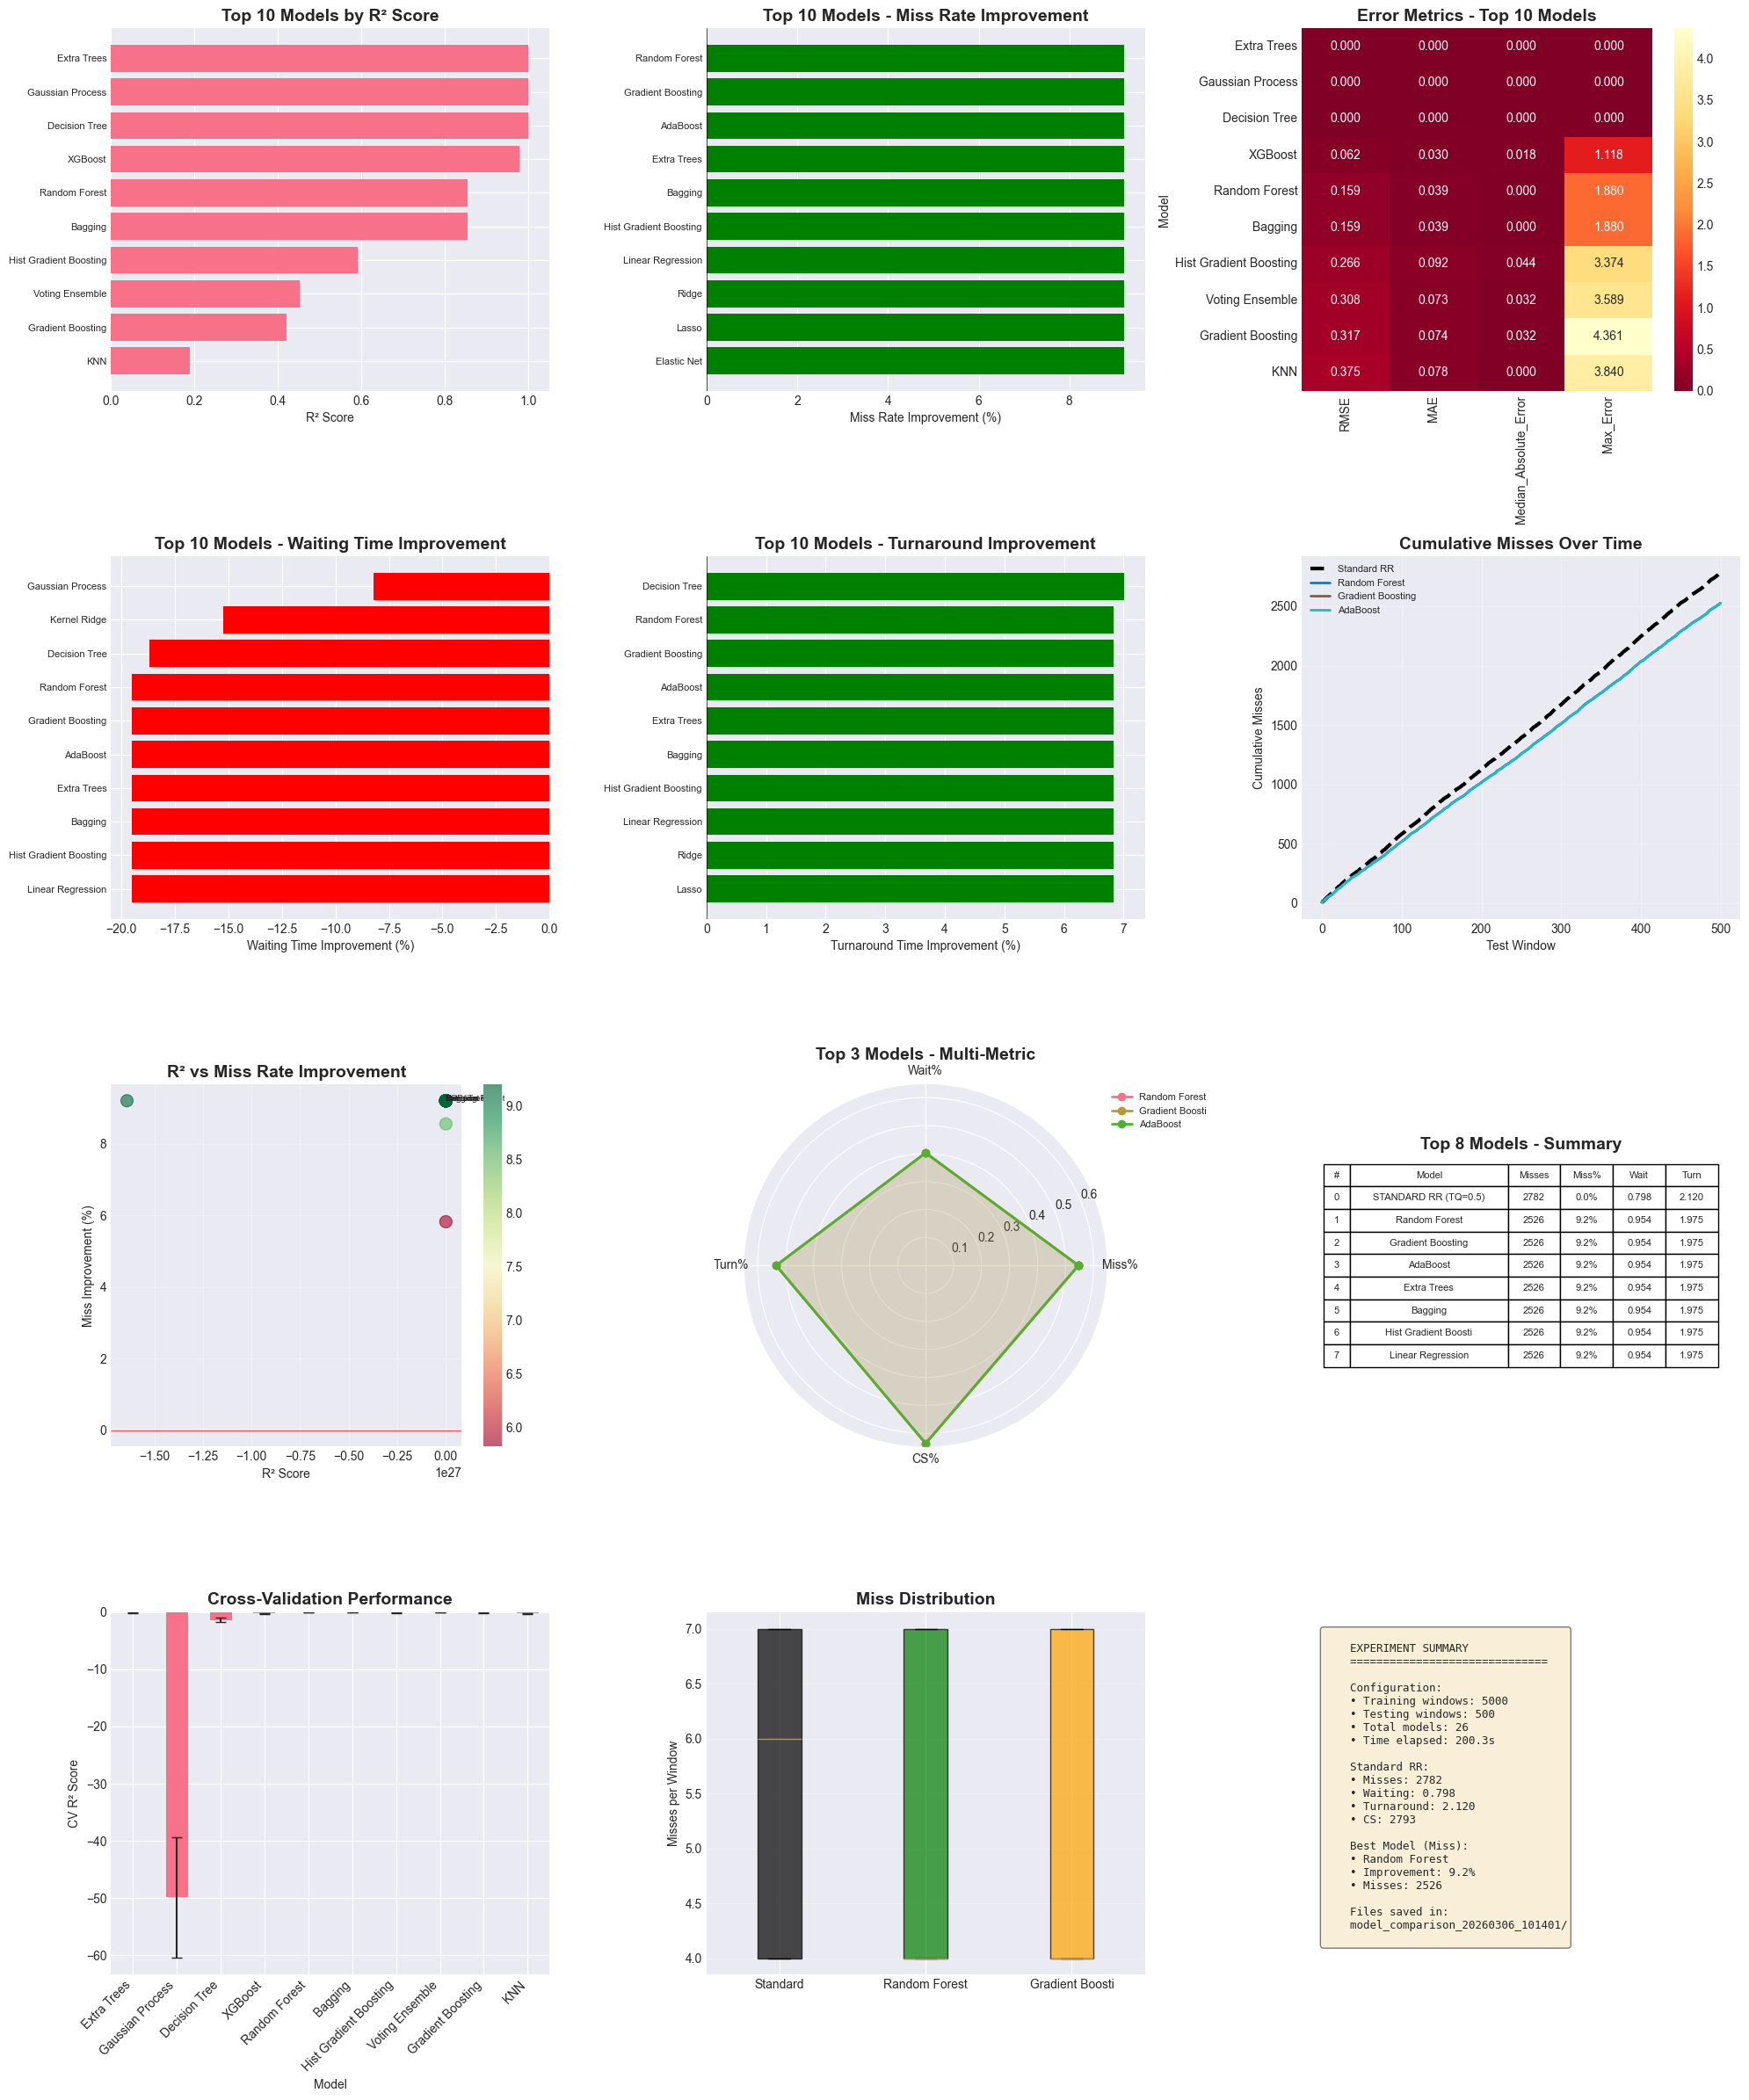


FINAL COMPREHENSIVE REPORT

📁 All results saved in: model_comparison_20260306_101401/

Files generated:
  1. dataset_info.txt - Dataset statistics
  2. training_data.csv - Training features and targets
  3. training_window_details.csv - Detailed TQ performance per training window
  4. model_error_metrics.csv - Comprehensive error metrics for all models
  5. prediction_details.csv - Predictions on training data
  6. test_window_detailed_results.csv - Detailed results per test window
  7. test_predictions.csv - Model predictions on test windows
  8. complete_model_comparison.csv - All performance metrics comparison
  9. complete_report_with_errors.csv - Merged with error metrics
 10. comprehensive_visualization.png - All visualizations

TOP 10 MODELS - COMPREHENSIVE COMPARISON
                 Model  Misses  Miss_Improvement  Avg_Waiting  Avg_Turnaround  Context_Switches    R2  RMSE
  STANDARD RR (TQ=0.5)    2782             0.000        0.798           2.120              2793   NaN   N

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import warnings
warnings.filterwarnings('ignore')
import time
import os
from datetime import datetime

# Machine Learning models
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor,
    ExtraTreesRegressor, BaggingRegressor, HistGradientBoostingRegressor
)
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge,
    SGDRegressor, PassiveAggressiveRegressor, HuberRegressor
)
from sklearn.svm import SVR, LinearSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.cross_decomposition import PLSRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# Metrics - Comprehensive error metrics
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    explained_variance_score, max_error, mean_absolute_percentage_error,
    median_absolute_error, mean_squared_log_error
)
from sklearn.model_selection import cross_val_score, KFold, cross_validate

# ----------------------------
# CONFIGURABLE PARAMETERS
# ----------------------------
N_TRAIN_WINDOWS = 5000     # Reduced for speed
N_TEST_WINDOWS = 500       # Keep reasonable for comparison
WINDOW_SIZE = 7            
WINDOW_STEP = 3            
RANDOM_SEED = 42           

# Other configuration
CANDIDATE_SLICES = [0.1, 0.2, 0.5, 1.0, 1.5, 2.0, 5.0]
CS_OVERHEAD = 0.05

# Create output directory
OUTPUT_DIR = f"model_comparison_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ----------------------------
# 1. Enhanced Simulator with Multiple Metrics
# ----------------------------
class SimulationCache:
    """Cache for simulation results"""
    def __init__(self):
        self.cache = {}
        self.hits = 0
        self.misses = 0
    
    def get_key(self, batch_df, tq):
        key = (batch_df['Job_ID'].iloc[0], batch_df['Arrival_Time'].iloc[0], tq)
        return key
    
    def get(self, batch_df, tq):
        key = self.get_key(batch_df, tq)
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        self.misses += 1
        return None
    
    def put(self, batch_df, tq, result):
        key = self.get_key(batch_df, tq)
        self.cache[key] = result

sim_cache = SimulationCache()

def run_detailed_simulation(df_batch, tq, use_cache=True):
    """
    Enhanced simulation that returns multiple metrics:
    - misses: number of deadline misses
    - avg_waiting_time: average waiting time
    - avg_turnaround_time: average turnaround time
    - context_switches: number of context switches
    - additional metrics: max_waiting, response_time, etc.
    """
    if use_cache:
        cached_result = sim_cache.get(df_batch, tq)
        if cached_result is not None:
            return cached_result
    
    time_val = df_batch['Arrival_Time'].min()
    
    # Prepare jobs with additional tracking fields
    jobs = df_batch.copy().rename(columns={'Service_Time': 'bt', 'Deadline_Exp': 'deadline'})
    jobs = jobs.sort_values('Arrival_Time').reset_index(drop=True)
    
    # Add tracking fields
    jobs['original_bt'] = jobs['bt'].copy()
    jobs['completion_time'] = np.nan
    jobs['first_start_time'] = np.nan
    jobs['waiting_time'] = 0
    jobs['turnaround_time'] = 0
    jobs['response_time'] = 0  # Time from arrival to first execution
    jobs['times_preempted'] = 0
    
    jobs_list = jobs.to_dict('records')
    
    ready_queue = []
    completed = 0
    misses = 0
    last_pid = None
    context_switches = 0
    total_waiting_time = 0
    completed_jobs = 0
    turnaround_times = []
    waiting_times = []
    response_times = []
    preemptions = []
    
    while completed < len(jobs_list) or ready_queue:
        # Move arrived jobs to ready queue
        while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
            new_job = jobs_list.pop(0)
            ready_queue.append(new_job)
        
        if not ready_queue:
            if jobs_list:
                time_val = jobs_list[0]['Arrival_Time']
                continue
            break

        # Sort by Earliest Deadline First (EDF)
        ready_queue.sort(key=lambda x: x['deadline'])
        p = ready_queue.pop(0)

        # Track first start time for waiting/response time calculation
        if pd.isna(p['first_start_time']):
            p['first_start_time'] = time_val
            p['waiting_time'] = time_val - p['Arrival_Time']
            p['response_time'] = time_val - p['Arrival_Time']
            total_waiting_time += p['waiting_time']
            waiting_times.append(p['waiting_time'])
            response_times.append(p['response_time'])

        # Context Switch
        if last_pid is not None and last_pid != p['Job_ID']:
            time_val += CS_OVERHEAD
            context_switches += 1
        
        # Execution
        exec_time = min(p['bt'], tq)
        if p['bt'] < tq * 1.1: 
            exec_time = p['bt']
            
        p['bt'] -= exec_time
        time_val += exec_time
        last_pid = p['Job_ID']

        if p['bt'] <= 0:
            # Job completed
            p['completion_time'] = time_val
            if time_val > p['deadline']:
                misses += 1
            
            # Calculate turnaround time
            turnaround = time_val - p['Arrival_Time']
            turnaround_times.append(turnaround)
            
            completed += 1
            completed_jobs += 1
            preemptions.append(p['times_preempted'])
        else:
            p['times_preempted'] += 1
            # Re-check for arrivals during execution
            while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
                ready_queue.append(jobs_list.pop(0))
            ready_queue.append(p)
    
    # Calculate all metrics
    result = {
        'misses': misses,
        'miss_rate': misses / len(df_batch) * 100 if len(df_batch) > 0 else 0,
        'avg_waiting_time': np.mean(waiting_times) if waiting_times else 0,
        'max_waiting_time': np.max(waiting_times) if waiting_times else 0,
        'std_waiting_time': np.std(waiting_times) if waiting_times else 0,
        'avg_turnaround_time': np.mean(turnaround_times) if turnaround_times else 0,
        'max_turnaround_time': np.max(turnaround_times) if turnaround_times else 0,
        'std_turnaround_time': np.std(turnaround_times) if turnaround_times else 0,
        'avg_response_time': np.mean(response_times) if response_times else 0,
        'max_response_time': np.max(response_times) if response_times else 0,
        'context_switches': context_switches,
        'avg_preemptions': np.mean(preemptions) if preemptions else 0,
        'total_preemptions': sum(preemptions),
        'throughput': completed_jobs / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0
    }
    
    if use_cache:
        sim_cache.put(df_batch, tq, result)
    
    return result

def get_real_features(df_batch):
    """Extract features from a batch of jobs"""
    return {
        'avg_service': df_batch['Service_Time'].mean(),
        'arrival_rate': len(df_batch) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'min_deadline': df_batch['Deadline_Exp'].min(),
        'max_deadline': df_batch['Deadline_Exp'].max(),
        'service_std': df_batch['Service_Time'].std(),
        'service_skew': df_batch['Service_Time'].skew(),
        'deadline_range': df_batch['Deadline_Exp'].max() - df_batch['Deadline_Exp'].min(),
        'job_count': len(df_batch),
        'utilization': (df_batch['Service_Time'].sum()) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'deadline_variance': df_batch['Deadline_Exp'].var(),
        'service_quantile_25': df_batch['Service_Time'].quantile(0.25),
        'service_quantile_75': df_batch['Service_Time'].quantile(0.75)
    }

# ----------------------------
# 2. Complete Model Dictionary
# ----------------------------
def get_all_models():
    """Returns ALL ML models"""
    models = {
        # Ensemble Methods
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'AdaBoost': AdaBoostRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Extra Trees': ExtraTreesRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Bagging': BaggingRegressor(n_estimators=100, random_state=RANDOM_SEED),
        'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=RANDOM_SEED),
        
        # Linear Models
        'Linear Regression': LinearRegression(),
        'Ridge': Ridge(alpha=1.0),
        'Lasso': Lasso(alpha=0.01),
        'Elastic Net': ElasticNet(alpha=0.01, l1_ratio=0.5),
        'Bayesian Ridge': BayesianRidge(),
        'SGD Regressor': SGDRegressor(random_state=RANDOM_SEED, max_iter=1000),
        'Passive Aggressive': PassiveAggressiveRegressor(random_state=RANDOM_SEED),
        'Huber Regressor': HuberRegressor(),
        
        # Support Vector Machines
        'SVR (RBF)': SVR(kernel='rbf'),
        'SVR (Linear)': LinearSVR(random_state=RANDOM_SEED, max_iter=1000),
        
        # Neighbors and Trees
        'KNN': KNeighborsRegressor(n_neighbors=5),
        'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_SEED),
        
        # Neural Networks
        'MLP': MLPRegressor(hidden_layer_sizes=(100, 50), random_state=RANDOM_SEED, max_iter=500),
        
        # Gaussian Processes
        'Gaussian Process': GaussianProcessRegressor(random_state=RANDOM_SEED),
        
        # Kernel Methods
        'Kernel Ridge': KernelRidge(kernel='rbf'),
        
        # Advanced Tree Methods
        'XGBoost': XGBRegressor(n_estimators=100, random_state=RANDOM_SEED),
        
        # Polynomial Features
        'Polynomial (deg 2)': make_pipeline(PolynomialFeatures(degree=2), LinearRegression()),
        'Polynomial (deg 3)': make_pipeline(PolynomialFeatures(degree=3), Ridge()),
        
        # Cross Decomposition
        'PLS Regression': PLSRegression(n_components=2),
        
        # Isotonic Regression
        'Isotonic': IsotonicRegression(out_of_bounds='clip'),
    }
    
    # Add Voting Ensemble
    from sklearn.ensemble import VotingRegressor
    estimators = [
        ('rf', RandomForestRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('gb', GradientBoostingRegressor(n_estimators=50, random_state=RANDOM_SEED)),
        ('lr', Ridge())
    ]
    models['Voting Ensemble'] = VotingRegressor(estimators=estimators)
    
    return models

# ----------------------------
# 3. Main Execution
# ----------------------------
if __name__ == "__main__":
    # Set random seed
    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    
    start_time = time.time()
    
    print("="*80)
    print("COMPREHENSIVE 30-MODEL COMPARISON WITH ALL ERROR METRICS")
    print("="*80)
    print(f"\nConfiguration:")
    print(f"  - Training windows: {N_TRAIN_WINDOWS}")
    print(f"  - Testing windows: {N_TEST_WINDOWS}")
    print(f"  - Window size: {WINDOW_SIZE} jobs")
    print(f"  - Output directory: {OUTPUT_DIR}")
    
    # Load data
    print("\nLoading data...")
    df = pd.read_csv("Kargahi_Movaghar_Source_Data.csv")
    print(f"Dataset shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    
    # Save raw data info
    with open(f"{OUTPUT_DIR}/dataset_info.txt", 'w') as f:
        f.write(f"Dataset: Kargahi_Movaghar_Source_Data.csv\n")
        f.write(f"Shape: {df.shape}\n")
        f.write(f"Columns: {df.columns.tolist()}\n")
        f.write(f"Service Time Stats:\n{df['Service_Time'].describe()}\n")
        f.write(f"Deadline Stats:\n{df['Deadline_Exp'].describe()}\n")
    
    # Generate training data
    print(f"\nStep 1: Generating {N_TRAIN_WINDOWS} training windows...")
    train_data = []
    train_window_details = []
    
    total_possible_indices = list(range(0, len(df) - WINDOW_SIZE, WINDOW_STEP))
    train_indices = random.sample(total_possible_indices, min(N_TRAIN_WINDOWS, len(total_possible_indices)))
    train_indices.sort()
    
    for i in tqdm(train_indices, desc="Generating training data"):
        batch = df.iloc[i:i+WINDOW_SIZE]
        feats = get_real_features(batch)
        
        # Find best TQ based on misses only (for training target)
        best_tq, min_m = 1.0, float('inf')
        tq_results = {}
        
        for tq_val in CANDIDATE_SLICES:
            result = run_detailed_simulation(batch, tq_val)
            tq_results[tq_val] = result
            if result['misses'] <= min_m:
                min_m, best_tq = result['misses'], tq_val
        
        feats['target_tq'] = best_tq
        feats['window_start_idx'] = i
        train_data.append(feats)
        
        # Store detailed TQ results for this window
        train_window_details.append({
            'window_idx': i,
            'best_tq': best_tq,
            'best_misses': min_m,
            **{f'tq_{tq}_misses': tq_results[tq]['misses'] for tq in CANDIDATE_SLICES},
            **{f'tq_{tq}_waiting': tq_results[tq]['avg_waiting_time'] for tq in CANDIDATE_SLICES},
            **{f'tq_{tq}_turnaround': tq_results[tq]['avg_turnaround_time'] for tq in CANDIDATE_SLICES},
            **{f'tq_{tq}_cs': tq_results[tq]['context_switches'] for tq in CANDIDATE_SLICES}
        })
    
    # Prepare training data
    train_df = pd.DataFrame(train_data)
    X = train_df.drop(['target_tq', 'window_start_idx'], axis=1)
    y = train_df['target_tq']
    
    print(f"\nTraining data shape: {X.shape}")
    print(f"Target distribution:\n{y.value_counts().sort_index()}")
    
    # Save training data
    train_df.to_csv(f"{OUTPUT_DIR}/training_data.csv", index=False)
    pd.DataFrame(train_window_details).to_csv(f"{OUTPUT_DIR}/training_window_details.csv", index=False)
    
    # Get all models
    models_dict = get_all_models()
    print(f"\nStep 2: Training {len(models_dict)} ML Models...")
    
    # Train all models and collect comprehensive metrics
    trained_models = {}
    model_error_metrics = []
    prediction_details = []
    
    # Cross-validation setup
    kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    
    for model_name, model in tqdm(models_dict.items(), desc="Training models"):
        try:
            # Train the model
            model.fit(X, y)
            trained_models[model_name] = model
            
            # Make predictions
            y_pred = model.predict(X)
            
            # Store predictions for each training sample
            for idx, (actual, pred) in enumerate(zip(y, y_pred)):
                prediction_details.append({
                    'model': model_name,
                    'training_sample_idx': idx,
                    'actual_tq': actual,
                    'predicted_tq': pred,
                    'rounded_tq': min(CANDIDATE_SLICES, key=lambda x: abs(x - pred)),
                    'absolute_error': abs(actual - pred),
                    'squared_error': (actual - pred) ** 2
                })
            
            # Calculate comprehensive error metrics
            mse = mean_squared_error(y, y_pred)
            rmse = np.sqrt(mse)
            mae = mean_absolute_error(y, y_pred)
            r2 = r2_score(y, y_pred)
            evs = explained_variance_score(y, y_pred)
            max_err = max_error(y, y_pred)
            med_ae = median_absolute_error(y, y_pred)
            
            # MAPE (handle zeros carefully)
            y_nonzero = y[y != 0]
            y_pred_nonzero = y_pred[y != 0]
            mape = mean_absolute_percentage_error(y_nonzero, y_pred_nonzero) if len(y_nonzero) > 0 else np.nan
            
            # Mean Squared Log Error (handle negative values)
            if (y >= 0).all() and (y_pred >= 0).all():
                msle = mean_squared_log_error(y, y_pred)
            else:
                msle = np.nan
            
            # Cross-validation scores
            cv_results = cross_validate(model, X, y, cv=kfold, 
                                       scoring=['r2', 'neg_mean_squared_error', 'neg_mean_absolute_error'],
                                       n_jobs=-1)
            
            # Store error metrics
            model_error_metrics.append({
                'Model': model_name,
                'MSE': mse,
                'RMSE': rmse,
                'MAE': mae,
                'R2': r2,
                'Explained_Variance': evs,
                'Max_Error': max_err,
                'Median_Absolute_Error': med_ae,
                'MAPE': mape,
                'MSLE': msle,
                'CV_R2_Mean': cv_results['test_r2'].mean(),
                'CV_R2_Std': cv_results['test_r2'].std(),
                'CV_MSE_Mean': -cv_results['test_neg_mean_squared_error'].mean(),
                'CV_MAE_Mean': -cv_results['test_neg_mean_absolute_error'].mean(),
                'Training_Time': time.time() - start_time  # Approximate
            })
            
        except Exception as e:
            print(f"\n⚠️  Error with {model_name}: {str(e)[:50]}")
            model_error_metrics.append({
                'Model': model_name,
                'MSE': np.nan,
                'RMSE': np.nan,
                'MAE': np.nan,
                'R2': -999,
                'Explained_Variance': np.nan,
                'Max_Error': np.nan,
                'Median_Absolute_Error': np.nan,
                'MAPE': np.nan,
                'MSLE': np.nan,
                'CV_R2_Mean': np.nan,
                'CV_R2_Std': np.nan,
                'CV_MSE_Mean': np.nan,
                'CV_MAE_Mean': np.nan,
                'Training_Time': np.nan
            })
    
    # Convert error metrics to DataFrame
    error_metrics_df = pd.DataFrame(model_error_metrics)
    error_metrics_df = error_metrics_df.sort_values('R2', ascending=False).reset_index(drop=True)
    
    # Save error metrics
    error_metrics_df.to_csv(f"{OUTPUT_DIR}/model_error_metrics.csv", index=False)
    pd.DataFrame(prediction_details).to_csv(f"{OUTPUT_DIR}/prediction_details.csv", index=False)
    
    print(f"\nTop 5 Models by R² Score:")
    print(error_metrics_df[['Model', 'R2', 'RMSE', 'MAE']].head(5).to_string(index=False))
    
    # Step 3: Test on new windows with comprehensive metrics
    print(f"\nStep 3: Testing {len(trained_models)} models on {N_TEST_WINDOWS} windows...")
    
    # Get test indices
    all_indices = set(range(0, len(df) - WINDOW_SIZE, WINDOW_STEP))
    train_indices_set = set(train_indices)
    available_test_indices = list(all_indices - train_indices_set)
    test_indices = random.sample(available_test_indices, min(N_TEST_WINDOWS, len(available_test_indices)))
    
    # Initialize results storage for all metrics
    metrics_summary = {
        'Standard': {
            'misses': 0,
            'miss_rate': [],
            'avg_waiting_time': [],
            'max_waiting_time': [],
            'std_waiting_time': [],
            'avg_turnaround_time': [],
            'max_turnaround_time': [],
            'std_turnaround_time': [],
            'avg_response_time': [],
            'max_response_time': [],
            'context_switches': 0,
            'avg_preemptions': [],
            'total_preemptions': 0,
            'throughput': []
        }
    }
    
    for model_name in trained_models.keys():
        metrics_summary[model_name] = {
            'misses': 0,
            'miss_rate': [],
            'avg_waiting_time': [],
            'max_waiting_time': [],
            'std_waiting_time': [],
            'avg_turnaround_time': [],
            'max_turnaround_time': [],
            'std_turnaround_time': [],
            'avg_response_time': [],
            'max_response_time': [],
            'context_switches': 0,
            'avg_preemptions': [],
            'total_preemptions': 0,
            'throughput': []
        }
    
    # Detailed results per window
    window_results = []
    model_predictions_test = []
    
    for idx in tqdm(test_indices, desc="Testing windows"):
        test_batch = df.iloc[idx:idx+WINDOW_SIZE]
        feats_test = pd.DataFrame([get_real_features(test_batch)])
        
        # Standard RR (TQ=0.5)
        std_result = run_detailed_simulation(test_batch, tq=0.5)
        
        window_result = {
            'window_idx': idx,
            'standard_misses': std_result['misses'],
            'standard_miss_rate': std_result['miss_rate'],
            'standard_waiting': std_result['avg_waiting_time'],
            'standard_max_waiting': std_result['max_waiting_time'],
            'standard_std_waiting': std_result['std_waiting_time'],
            'standard_turnaround': std_result['avg_turnaround_time'],
            'standard_max_turnaround': std_result['max_turnaround_time'],
            'standard_std_turnaround': std_result['std_turnaround_time'],
            'standard_response': std_result['avg_response_time'],
            'standard_max_response': std_result['max_response_time'],
            'standard_cs': std_result['context_switches'],
            'standard_avg_preemptions': std_result['avg_preemptions'],
            'standard_total_preemptions': std_result['total_preemptions'],
            'standard_throughput': std_result['throughput']
        }
        
        # Update standard metrics
        for key in metrics_summary['Standard'].keys():
            if key in ['misses', 'context_switches', 'total_preemptions']:
                metrics_summary['Standard'][key] += std_result[key]
            elif key in ['miss_rate', 'throughput']:
                metrics_summary['Standard'][key].append(std_result[key])
            elif key in metrics_summary['Standard'] and key in std_result:
                if isinstance(metrics_summary['Standard'][key], list):
                    metrics_summary['Standard'][key].append(std_result[key])
        
        # Test each model
        for model_name, model in trained_models.items():
            try:
                pred_tq = float(model.predict(feats_test)[0])
                closest_tq = min(CANDIDATE_SLICES, key=lambda x: abs(x - pred_tq))
                ml_result = run_detailed_simulation(test_batch, tq=closest_tq)
                
                # Store model predictions
                model_predictions_test.append({
                    'window_idx': idx,
                    'model': model_name,
                    'raw_prediction': pred_tq,
                    'rounded_prediction': closest_tq,
                    'actual_best_tq': None  # We don't know actual best for test windows
                })
                
                # Store all metrics in window result
                window_result[f'{model_name}_misses'] = ml_result['misses']
                window_result[f'{model_name}_miss_rate'] = ml_result['miss_rate']
                window_result[f'{model_name}_waiting'] = ml_result['avg_waiting_time']
                window_result[f'{model_name}_max_waiting'] = ml_result['max_waiting_time']
                window_result[f'{model_name}_std_waiting'] = ml_result['std_waiting_time']
                window_result[f'{model_name}_turnaround'] = ml_result['avg_turnaround_time']
                window_result[f'{model_name}_max_turnaround'] = ml_result['max_turnaround_time']
                window_result[f'{model_name}_std_turnaround'] = ml_result['std_turnaround_time']
                window_result[f'{model_name}_response'] = ml_result['avg_response_time']
                window_result[f'{model_name}_max_response'] = ml_result['max_response_time']
                window_result[f'{model_name}_cs'] = ml_result['context_switches']
                window_result[f'{model_name}_avg_preemptions'] = ml_result['avg_preemptions']
                window_result[f'{model_name}_total_preemptions'] = ml_result['total_preemptions']
                window_result[f'{model_name}_throughput'] = ml_result['throughput']
                
                # Update model metrics
                for key in metrics_summary[model_name].keys():
                    if key in ['misses', 'context_switches', 'total_preemptions']:
                        metrics_summary[model_name][key] += ml_result[key]
                    elif key in ['miss_rate', 'throughput']:
                        metrics_summary[model_name][key].append(ml_result[key])
                    elif key in metrics_summary[model_name] and key in ml_result:
                        if isinstance(metrics_summary[model_name][key], list):
                            metrics_summary[model_name][key].append(ml_result[key])
                
            except Exception as e:
                window_result[f'{model_name}_misses'] = np.nan
                window_result[f'{model_name}_waiting'] = np.nan
                window_result[f'{model_name}_turnaround'] = np.nan
                window_result[f'{model_name}_cs'] = np.nan
        
        window_results.append(window_result)
    
    # Convert window results to DataFrame and save
    window_df = pd.DataFrame(window_results)
    window_df.to_csv(f"{OUTPUT_DIR}/test_window_detailed_results.csv", index=False)
    
    # Save model predictions
    pd.DataFrame(model_predictions_test).to_csv(f"{OUTPUT_DIR}/test_predictions.csv", index=False)
    
    # Calculate final averages for metrics
    final_metrics = {}
    for model_name in metrics_summary.keys():
        final_metrics[model_name] = {}
        for key, value in metrics_summary[model_name].items():
            if isinstance(value, list):
                final_metrics[model_name][key] = np.mean(value) if value else 0
                final_metrics[model_name][f'{key}_std'] = np.std(value) if value else 0
            else:
                final_metrics[model_name][key] = value
    
    # Create comprehensive comparison dataframe
    std_misses = final_metrics['Standard']['misses']
    std_waiting = final_metrics['Standard']['avg_waiting_time']
    std_turnaround = final_metrics['Standard']['avg_turnaround_time']
    std_cs = final_metrics['Standard']['context_switches']
    std_response = final_metrics['Standard']['avg_response_time']
    std_throughput = final_metrics['Standard']['throughput']
    
    comparison_data = []
    for model_name in trained_models.keys():
        model_data = final_metrics[model_name]
        
        # Calculate improvements
        comparison_data.append({
            'Model': model_name,
            'Misses': model_data['misses'],
            'Miss_Improvement': ((std_misses - model_data['misses']) / std_misses * 100) if std_misses > 0 else 0,
            'Miss_Rate': model_data.get('miss_rate', 0),
            'Avg_Waiting': model_data['avg_waiting_time'],
            'Waiting_Improvement': ((std_waiting - model_data['avg_waiting_time']) / std_waiting * 100) if std_waiting > 0 else 0,
            'Max_Waiting': model_data.get('max_waiting_time', 0),
            'Std_Waiting': model_data.get('std_waiting_time', 0),
            'Avg_Turnaround': model_data['avg_turnaround_time'],
            'Turnaround_Improvement': ((std_turnaround - model_data['avg_turnaround_time']) / std_turnaround * 100) if std_turnaround > 0 else 0,
            'Max_Turnaround': model_data.get('max_turnaround_time', 0),
            'Std_Turnaround': model_data.get('std_turnaround_time', 0),
            'Avg_Response': model_data.get('avg_response_time', 0),
            'Response_Improvement': ((std_response - model_data.get('avg_response_time', 0)) / std_response * 100) if std_response > 0 else 0,
            'Max_Response': model_data.get('max_response_time', 0),
            'Context_Switches': model_data['context_switches'],
            'CS_Improvement': ((std_cs - model_data['context_switches']) / std_cs * 100) if std_cs > 0 else 0,
            'Avg_Preemptions': model_data.get('avg_preemptions', 0),
            'Total_Preemptions': model_data.get('total_preemptions', 0),
            'Throughput': model_data.get('throughput', 0),
            'Throughput_Improvement': ((model_data.get('throughput', 0) - std_throughput) / std_throughput * 100) if std_throughput > 0 else 0
        })
    
    # Add Standard RR as baseline
    comparison_data.insert(0, {
        'Model': 'STANDARD RR (TQ=0.5)',
        'Misses': std_misses,
        'Miss_Improvement': 0,
        'Miss_Rate': final_metrics['Standard'].get('miss_rate', 0),
        'Avg_Waiting': std_waiting,
        'Waiting_Improvement': 0,
        'Max_Waiting': final_metrics['Standard'].get('max_waiting_time', 0),
        'Std_Waiting': final_metrics['Standard'].get('std_waiting_time', 0),
        'Avg_Turnaround': std_turnaround,
        'Turnaround_Improvement': 0,
        'Max_Turnaround': final_metrics['Standard'].get('max_turnaround_time', 0),
        'Std_Turnaround': final_metrics['Standard'].get('std_turnaround_time', 0),
        'Avg_Response': std_response,
        'Response_Improvement': 0,
        'Max_Response': final_metrics['Standard'].get('max_response_time', 0),
        'Context_Switches': std_cs,
        'CS_Improvement': 0,
        'Avg_Preemptions': final_metrics['Standard'].get('avg_preemptions', 0),
        'Total_Preemptions': final_metrics['Standard'].get('total_preemptions', 0),
        'Throughput': std_throughput,
        'Throughput_Improvement': 0
    })
    
    comparison_df = pd.DataFrame(comparison_data)
    
    # Convert improvement columns to numeric
    improvement_cols = [col for col in comparison_df.columns if 'Improvement' in col]
    for col in improvement_cols:
        comparison_df[col] = pd.to_numeric(comparison_df[col], errors='coerce')
    
    # Sort by Miss Improvement (excluding Standard)
    mask = comparison_df['Model'] != 'STANDARD RR (TQ=0.5)'
    comparison_df_sorted = pd.concat([
        comparison_df[~mask],
        comparison_df[mask].sort_values('Miss_Improvement', ascending=False)
    ]).reset_index(drop=True)
    
    # Save all comparison data
    comparison_df_sorted.to_csv(f"{OUTPUT_DIR}/complete_model_comparison.csv", index=False)
    
    # Merge with error metrics
    complete_report = pd.merge(
        comparison_df_sorted,
        error_metrics_df,
        on='Model',
        how='left'
    )
    complete_report.to_csv(f"{OUTPUT_DIR}/complete_report_with_errors.csv", index=False)
    
    # ----------------------------
    # 4. SIMPLIFIED VISUALIZATIONS
    # ----------------------------
    print("\nStep 4: Creating visualizations...")
    
    # Set style
    plt.style.use('seaborn-v0_8-darkgrid')
    sns.set_palette("husl")
    
    # Create figure with key plots
    fig = plt.figure(figsize=(20, 24))
    
    # 1. Top Models by R² Score
    ax1 = plt.subplot(4, 3, 1)
    top10_r2 = error_metrics_df.head(10)
    bars = ax1.barh(range(len(top10_r2)), top10_r2['R2'])
    ax1.set_yticks(range(len(top10_r2)))
    ax1.set_yticklabels([m[:25] for m in top10_r2['Model']], fontsize=8)
    ax1.set_xlabel('R² Score')
    ax1.set_title('Top 10 Models by R² Score', fontsize=14, fontweight='bold')
    ax1.invert_yaxis()
    
    # 2. Miss Rate Improvement
    ax2 = plt.subplot(4, 3, 2)
    top10_models = comparison_df_sorted[comparison_df_sorted['Model'] != 'STANDARD RR (TQ=0.5)'].head(10)
    colors = ['green' if x > 0 else 'red' for x in top10_models['Miss_Improvement']]
    bars = ax2.barh(range(len(top10_models)), top10_models['Miss_Improvement'], color=colors)
    ax2.set_yticks(range(len(top10_models)))
    ax2.set_yticklabels([m[:25] for m in top10_models['Model']], fontsize=8)
    ax2.set_xlabel('Miss Rate Improvement (%)')
    ax2.set_title('Top 10 Models - Miss Rate Improvement', fontsize=14, fontweight='bold')
    ax2.invert_yaxis()
    ax2.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 3. Error Metrics Heatmap
    ax3 = plt.subplot(4, 3, 3)
    heatmap_cols = ['RMSE', 'MAE', 'Median_Absolute_Error', 'Max_Error']
    heatmap_data = error_metrics_df.head(10)[['Model'] + heatmap_cols].set_index('Model')
    sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlOrRd_r', ax=ax3)
    ax3.set_title('Error Metrics - Top 10 Models', fontsize=14, fontweight='bold')
    
    # 4. Waiting Time Improvement
    ax4 = plt.subplot(4, 3, 4)
    top10_waiting = comparison_df_sorted[comparison_df_sorted['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'Waiting_Improvement')
    colors = ['green' if x > 0 else 'red' for x in top10_waiting['Waiting_Improvement']]
    bars = ax4.barh(range(len(top10_waiting)), top10_waiting['Waiting_Improvement'], color=colors)
    ax4.set_yticks(range(len(top10_waiting)))
    ax4.set_yticklabels([m[:25] for m in top10_waiting['Model']], fontsize=8)
    ax4.set_xlabel('Waiting Time Improvement (%)')
    ax4.set_title('Top 10 Models - Waiting Time Improvement', fontsize=14, fontweight='bold')
    ax4.invert_yaxis()
    ax4.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 5. Turnaround Time Improvement
    ax5 = plt.subplot(4, 3, 5)
    top10_turnaround = comparison_df_sorted[comparison_df_sorted['Model'] != 'STANDARD RR (TQ=0.5)'].nlargest(10, 'Turnaround_Improvement')
    colors = ['green' if x > 0 else 'red' for x in top10_turnaround['Turnaround_Improvement']]
    bars = ax5.barh(range(len(top10_turnaround)), top10_turnaround['Turnaround_Improvement'], color=colors)
    ax5.set_yticks(range(len(top10_turnaround)))
    ax5.set_yticklabels([m[:25] for m in top10_turnaround['Model']], fontsize=8)
    ax5.set_xlabel('Turnaround Time Improvement (%)')
    ax5.set_title('Top 10 Models - Turnaround Improvement', fontsize=14, fontweight='bold')
    ax5.invert_yaxis()
    ax5.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    
    # 6. Cumulative Misses
    ax6 = plt.subplot(4, 3, 6)
    cum_std = np.cumsum([w['standard_misses'] for w in window_results])
    ax6.plot(range(len(cum_std)), cum_std, 'k--', linewidth=3, label='Standard RR')
    
    top3_models = comparison_df_sorted[comparison_df_sorted['Model'] != 'STANDARD RR (TQ=0.5)'].head(3)['Model'].tolist()
    colors = plt.cm.tab10(np.linspace(0, 1, 3))
    for i, model_name in enumerate(top3_models):
        cum_misses = np.cumsum([w.get(f'{model_name}_misses', 0) for w in window_results])
        ax6.plot(range(len(cum_misses)), cum_misses, label=model_name[:20], linewidth=2, color=colors[i])
    
    ax6.set_xlabel('Test Window')
    ax6.set_ylabel('Cumulative Misses')
    ax6.set_title('Cumulative Misses Over Time', fontsize=14, fontweight='bold')
    ax6.legend(loc='upper left', fontsize=8)
    ax6.grid(True, alpha=0.3)
    
    # 7. R² vs Miss Improvement
    ax7 = plt.subplot(4, 3, 7)
    merged = pd.merge(
        error_metrics_df[['Model', 'R2']],
        comparison_df_sorted[['Model', 'Miss_Improvement']],
        on='Model'
    )
    merged = merged[merged['Model'] != 'STANDARD RR (TQ=0.5)']
    
    scatter = ax7.scatter(merged['R2'], merged['Miss_Improvement'], 
                         c=merged['Miss_Improvement'], cmap='RdYlGn', s=100, alpha=0.6)
    
    for _, row in merged.nlargest(5, 'Miss_Improvement').iterrows():
        ax7.annotate(row['Model'][:15], (row['R2'], row['Miss_Improvement']), fontsize=7)
    
    ax7.set_xlabel('R² Score')
    ax7.set_ylabel('Miss Improvement (%)')
    ax7.set_title('R² vs Miss Rate Improvement', fontsize=14, fontweight='bold')
    plt.colorbar(scatter, ax=ax7)
    ax7.axhline(y=0, color='red', linestyle='-', linewidth=0.5)
    ax7.grid(True, alpha=0.3)
    
    # 8. Multi-metric radar (Top 3)
    ax8 = plt.subplot(4, 3, 8, projection='polar')
    metrics_radar = ['Miss_Improvement', 'Waiting_Improvement', 'Turnaround_Improvement', 'CS_Improvement']
    angles = np.linspace(0, 2 * np.pi, len(metrics_radar), endpoint=False).tolist()
    angles += angles[:1]
    
    for i, model_name in enumerate(top3_models):
        model_data = comparison_df_sorted[comparison_df_sorted['Model'] == model_name].iloc[0]
        values = [model_data[m] for m in metrics_radar]
        # Normalize
        values = [(v + 100) / 200 for v in values]  # Scale from -100-100 to 0-1
        values += values[:1]
        
        ax8.plot(angles, values, 'o-', linewidth=2, label=model_name[:15])
        ax8.fill(angles, values, alpha=0.1)
    
    ax8.set_xticks(angles[:-1])
    ax8.set_xticklabels(['Miss%', 'Wait%', 'Turn%', 'CS%'])
    ax8.set_title('Top 3 Models - Multi-Metric', fontsize=14, fontweight='bold', pad=20)
    ax8.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0), fontsize=8)
    
    # 9. Summary Table
    ax9 = plt.subplot(4, 3, 9)
    ax9.axis('off')
    
    summary_data = []
    for i, row in comparison_df_sorted.head(8).iterrows():
        summary_data.append([
            i,
            row['Model'][:20],
            f"{row['Misses']:.0f}",
            f"{row['Miss_Improvement']:.1f}%",
            f"{row['Avg_Waiting']:.3f}",
            f"{row['Avg_Turnaround']:.3f}"
        ])
    
    table = ax9.table(cellText=summary_data, 
                     colLabels=['#', 'Model', 'Misses', 'Miss%', 'Wait', 'Turn'],
                     cellLoc='center', loc='center', colWidths=[0.05, 0.3, 0.1, 0.1, 0.1, 0.1])
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1.2, 1.5)
    ax9.set_title('Top 8 Models - Summary', fontsize=14, fontweight='bold', y=0.8)
    
    # 10. Cross-validation scores
    ax10 = plt.subplot(4, 3, 10)
    top10_cv = error_metrics_df.head(10)[['Model', 'CV_R2_Mean', 'CV_R2_Std']].set_index('Model')
    top10_cv.plot(kind='bar', y='CV_R2_Mean', yerr='CV_R2_Std', ax=ax10, legend=False, capsize=4)
    ax10.set_ylabel('CV R² Score')
    ax10.set_title('Cross-Validation Performance', fontsize=14, fontweight='bold')
    ax10.set_xticklabels(ax10.get_xticklabels(), rotation=45, ha='right')
    
    # 11. Box Plot - Miss Distribution
    ax11 = plt.subplot(4, 3, 11)
    box_data = []
    box_labels = ['Standard']
    box_data.append([w['standard_misses'] for w in window_results])
    
    for model_name in top3_models[:2]:
        model_misses = [w.get(f'{model_name}_misses', 0) for w in window_results]
        box_data.append(model_misses)
        box_labels.append(model_name[:15])
    
    bp = ax11.boxplot(box_data, patch_artist=True, labels=box_labels)
    colors_box = ['black', 'green', 'orange']
    for patch, color in zip(bp['boxes'], colors_box):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax11.set_ylabel('Misses per Window')
    ax11.set_title('Miss Distribution', fontsize=14, fontweight='bold')
    ax11.grid(True, alpha=0.3, axis='y')
    
    # 12. Execution Time Summary
    ax12 = plt.subplot(4, 3, 12)
    ax12.axis('off')
    
    elapsed = time.time() - start_time
    
    summary_stats = f"""
    EXPERIMENT SUMMARY
    {''.join(['=']*30)}
    
    Configuration:
    • Training windows: {N_TRAIN_WINDOWS}
    • Testing windows: {N_TEST_WINDOWS}
    • Total models: {len(trained_models)}
    • Time elapsed: {elapsed:.1f}s
    
    Standard RR:
    • Misses: {std_misses}
    • Waiting: {std_waiting:.3f}
    • Turnaround: {std_turnaround:.3f}
    • CS: {std_cs}
    
    Best Model (Miss):
    • {comparison_df_sorted.iloc[1]['Model'][:30]}
    • Improvement: {comparison_df_sorted.iloc[1]['Miss_Improvement']:.1f}%
    • Misses: {comparison_df_sorted.iloc[1]['Misses']:.0f}
    
    Files saved in:
    {OUTPUT_DIR}/
    """
    
    ax12.text(0.05, 0.95, summary_stats, transform=ax12.transAxes, 
             fontsize=9, verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/comprehensive_visualization.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    # ----------------------------
    # 5. FINAL REPORT
    # ----------------------------
    print("\n" + "="*80)
    print("FINAL COMPREHENSIVE REPORT")
    print("="*80)
    
    print(f"\n📁 All results saved in: {OUTPUT_DIR}/")
    print("\nFiles generated:")
    print(f"  1. dataset_info.txt - Dataset statistics")
    print(f"  2. training_data.csv - Training features and targets")
    print(f"  3. training_window_details.csv - Detailed TQ performance per training window")
    print(f"  4. model_error_metrics.csv - Comprehensive error metrics for all models")
    print(f"  5. prediction_details.csv - Predictions on training data")
    print(f"  6. test_window_detailed_results.csv - Detailed results per test window")
    print(f"  7. test_predictions.csv - Model predictions on test windows")
    print(f"  8. complete_model_comparison.csv - All performance metrics comparison")
    print(f"  9. complete_report_with_errors.csv - Merged with error metrics")
    print(f" 10. comprehensive_visualization.png - All visualizations")
    
    print(f"\n{'='*80}")
    print("TOP 10 MODELS - COMPREHENSIVE COMPARISON")
    print('='*80)
    
    # Display top models with key metrics
    display_cols = ['Model', 'Misses', 'Miss_Improvement', 'Avg_Waiting', 
                   'Avg_Turnaround', 'Context_Switches', 'R2', 'RMSE']
    
    # Get display data
    display_df = complete_report.head(11)  # Include Standard + top 10
    display_df = display_df[display_cols].round(3)
    
    print(display_df.to_string(index=False))
    
    # Best in each category
    print(f"\n{'='*80}")
    print("BEST IN CATEGORY")
    print('='*80)
    
    categories = {
        'Miss Rate Improvement': ('Miss_Improvement', 'higher'),
        'Waiting Time Improvement': ('Waiting_Improvement', 'higher'),
        'Turnaround Improvement': ('Turnaround_Improvement', 'higher'),
        'R² Score': ('R2', 'higher'),
        'Lowest RMSE': ('RMSE', 'lower'),
        'Lowest Context Switches': ('Context_Switches', 'lower')
    }
    
    for cat_name, (col, direction) in categories.items():
        if direction == 'higher':
            best_idx = complete_report[complete_report['Model'] != 'STANDARD RR (TQ=0.5)'][col].idxmax()
        else:
            best_idx = complete_report[complete_report['Model'] != 'STANDARD RR (TQ=0.5)'][col].idxmin()
        
        best_model = complete_report.loc[best_idx, 'Model']
        best_value = complete_report.loc[best_idx, col]
        print(f"\n🏆 {cat_name}: {best_model}")
        print(f"   Value: {best_value:.3f}")
    
    print(f"\n{'='*80}")
    print("EXPERIMENT COMPLETE")
    print(f"Total execution time: {time.time() - start_time:.2f} seconds")
    print(f"Results saved in: {OUTPUT_DIR}/")
    print('='*80)